# Exploratory Data Analysis (EDA) — Machine Sound Dataset

This notebook performs a comprehensive **Exploratory Data Analysis (EDA)** on a multi-machine industrial sound dataset, designed to support the development of an anomaly-detection model using Convolutional Neural Networks (CNNs).

The dataset contains raw `.wav` audio files recorded from **three different machines**, each in either a **Normal** or **Abnormal** operating state. The data is organized into 6 classes:

| Label | Class                |
| ----- | -------------------- |
| 0     | Machine 1 — Normal   |
| 1     | Machine 1 — Abnormal |
| 2     | Machine 2 — Normal   |
| 3     | Machine 2 — Abnormal |
| 4     | Machine 3 — Normal   |
| 5     | Machine 3 — Abnormal |

---

## Notebook Structure

1. **Setup & Imports** — load required libraries
2. **Data Loading & Metadata Extraction** — scan `.wav` files, build a structured metadata DataFrame
3. **Dataset Statistics** — class distribution, audio duration, sample rate
4. **Waveform Visualization** — compare raw audio waveforms (Normal vs. Abnormal per machine)
5. **Spectral Analysis** — Mel-spectrogram, Power Spectral Density (PSD), and Spectral Centroid per machine
6. **CNN-Oriented EDA** — averaged PSD and small-multiples spectrograms tailored for CNN feature intuition
7. **Dimensionality Reduction (t-SNE)** — visualize feature separability across all 6 classes


---

## 1. Setup & Imports

Import standard analytics libraries (`numpy`, `pandas`) as well as `torchaudio`, which is used for efficient audio processing in the Kaggle/PyTorch environment.


In [1]:
# This Python 3 environment comes with many helpful analytics libraries installed
# It is defined by the kaggle/python Docker image: https://github.com/kaggle/docker-python
# For example, here's several helpful packages to load

import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)
import os
import torchaudio
from pathlib import Path

# Input data files are available in the read-only "../input/" directory
# For example, running this (by clicking run or pressing Shift+Enter) will list all files under the input directory
# You can write up to 20GB to the current directory (/kaggle/working/) that gets preserved as output when you create a version using "Save & Run All" 
# You can also write temporary files to /kaggle/temp/, but they won't be saved outside of the current session

---

## 2. Data Loading & Metadata Extraction

### 2.1 Dataset Path

Point to the root of the dataset on Kaggle's filesystem. The dataset is mounted as a read-only input and contains one folder per machine, each with `Normal/` and `Abnormal/` sub-directories of `.wav` files.


In [2]:
dataset_path = "/kaggle/input/datasets/alieldinalaa/nn-cmp27-dataset"

### 2.2 Metadata DataFrame Builder

`build_metadata_dataframe()` recursively walks the dataset directory tree and — using Python's built-in `wave` module — extracts lightweight metadata (sample rate, number of frames, duration) for every `.wav` file **without loading raw audio into memory**. This avoids RAM spikes on large datasets.

Each file is assigned an integer label (**0–5**) according to the machine/condition mapping defined above.


In [3]:
import os
import pandas as pd
import wave
from pathlib import Path

def build_metadata_dataframe(base_path):
    """
    Scans the dataset strictly extracting metadata using Python's native wave module to prevent RAM crashes and backend errors.
    """
    data = []
    
    # Strict mapping based on the project document's 0-5 class requirements
    label_map = {
        'Machine 1_Normal': 0,
        'Machine 1_Abnormal': 1,
        'Machine 2_Normal': 2,
        'Machine 2_Abnormal': 3,
        'Machine 3_Normal': 4,
        'Machine 3_Abnormal': 5
    }
    
    base_dir = Path(base_path)
    
    # 1. Iterate through Machine folders
    for machine_dir in base_dir.iterdir():
        if not machine_dir.is_dir(): 
            continue
            
        machine_name = machine_dir.name # e.g., "Machine 1"
        data_dir = machine_dir / "machine_data"
        
        if not data_dir.exists(): 
            continue
            
        # 2. Iterate through Normal and Abnormal folders
        for condition_dir in data_dir.iterdir():
            if not condition_dir.is_dir(): 
                continue
                
            condition = condition_dir.name # "Normal" or "Abnormal"
            class_key = f"{machine_name}_{condition}"
            label = label_map.get(class_key, -1)
            
            if label == -1: 
                continue
            
            # 3. Scan all .wav files in this specific directory
            for wav_file in condition_dir.glob("*.wav"):
                try:
                    # Fast metadata extraction using native wave module
                    with wave.open(str(wav_file), 'rb') as f:
                        sample_rate = f.getframerate()
                        num_frames = f.getnframes()
                        duration = num_frames / sample_rate
                    
                    data.append({
                        'file_path': str(wav_file),
                        'machine': machine_name,
                        'condition': condition,
                        'label': label,
                        'sample_rate': sample_rate,
                        'duration_sec': duration,
                        'num_frames': num_frames
                    })
                except Exception as e:
                    print(f"Error reading {wav_file.name}: {e}")
                    
    df = pd.DataFrame(data)
    return df

### 2.3 Stratified EDA Sampler

`get_eda_sample()` draws a fixed, reproducible random sample (default: 50 files per class) from the full metadata DataFrame. This lightweight sub-sample is later used for computationally-expensive plots (waveforms, spectrograms) so the notebook runs in a reasonable time.


In [4]:
def get_eda_sample(df, samples_per_class=50):
    """
    Performs stratified sampling to get a lightweight DataFrame for EDA plotting.
    """
    # Group by the label and randomly sample N rows from each class
    sampled_df = df.groupby('label', group_keys=False).apply(
        lambda x: x.sample(min(len(x), samples_per_class), random_state=42)
    )
    return sampled_df.reset_index(drop=True)

### 2.4 Build the Full Metadata DataFrame

Scan the entire dataset. This step touches every `.wav` file on disk and may take several minutes on the first run.


In [5]:
df = build_metadata_dataframe(dataset_path)

### 2.5 Cache Metadata to CSV

Persist the extracted metadata to CSV so subsequent runs can skip the scanning step entirely.


In [6]:
df.to_csv('/kaggle/working/dataset_metadata.csv', index=False)

### 2.6 Prepare Working DataFrames

- **`full_df`** — the complete metadata DataFrame (56 K+ rows), used for aggregate statistics.
- **`eda_df`** — a stratified 50-sample-per-class sub-set, used for audio loading and visualization.

> ⚠️ **FutureWarning** — The warning about `DataFrameGroupBy.apply` operating on grouping columns is a known Pandas deprecation notice and does not affect correctness. It will be resolved in a future Pandas release.


In [7]:
full_df = df
eda_df = get_eda_sample(df)

/tmp/ipykernel_16/612969121.py:6: FutureWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  sampled_df = df.groupby('label', group_keys=False).apply(


---

## 3. Dataset Statistics

A high-level look at the overall composition of the dataset: how many files exist per class, how long each recording is, and what sample rate they share.


### 3.1 Class Distribution

Count the number of audio files per class label (0–5) across the **entire** dataset.


/tmp/ipykernel_16/744993524.py:9: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(data=full_df, x='label', palette='viridis')


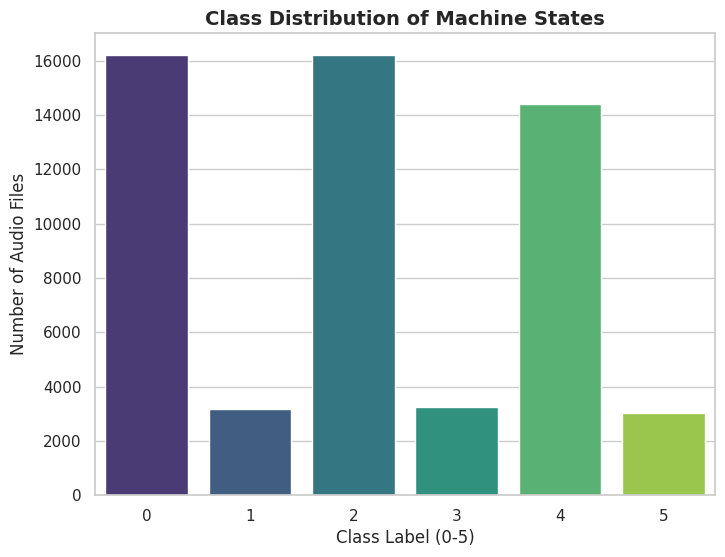

=== Exact Class Counts ===
label
0    16200
1     3176
2    16200
3     3240
4    14400
5     3020
Name: count, dtype: int64

Total Files: 56236


In [8]:
import matplotlib.pyplot as plt
import seaborn as sns

# Set a clean visual style for the notebook
sns.set_theme(style="whitegrid")

# 1. Plot the Bar Chart
plt.figure(figsize=(8, 6))
sns.countplot(data=full_df, x='label', palette='viridis')
plt.title('Class Distribution of Machine States', fontsize=14, fontweight='bold')
plt.xlabel('Class Label (0-5)', fontsize=12)
plt.ylabel('Number of Audio Files', fontsize=12)
plt.show()

# 2. Print the exact numbers to the console
print("=== Exact Class Counts ===")
exact_counts = full_df['label'].value_counts().sort_index()
print(exact_counts)

# Calculate the percentage of Abnormal vs Normal
total_files = len(full_df)
print(f"\nTotal Files: {total_files}")

**Output observations:**

- The dataset is **heavily imbalanced**: Normal classes (0, 2, 4) each hold roughly **14 400–16 200 files**, while Abnormal classes (1, 3, 5) have only **3 020–3 240 files** — an approximate **5 : 1 normal-to-abnormal ratio** per machine.
- This imbalance is realistic for industrial anomaly detection (failures are rare events) but will need to be addressed during model training (e.g., class weighting, oversampling, or threshold tuning).
- Machine 3 (labels 4 & 5) has slightly fewer Normal samples (14 400 vs. 16 200) compared to Machines 1 and 2, suggesting a different recording session length or design choice.


### 3.2 Audio Duration Distribution

Inspect the range and spread of clip lengths across all 56 K+ files.


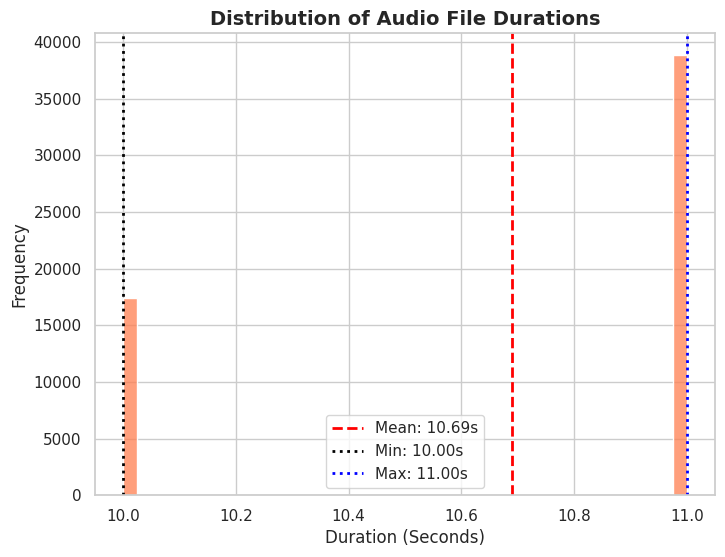

=== Duration Statistics ===
Absolute Minimum: 10.000 seconds
Absolute Maximum: 11.000 seconds
Average Length:   10.690 seconds


In [9]:
# 1. Plot the Histogram
plt.figure(figsize=(8, 6))
sns.histplot(data=full_df, x='duration_sec', bins=40, color='coral')
plt.title('Distribution of Audio File Durations', fontsize=14, fontweight='bold')
plt.xlabel('Duration (Seconds)', fontsize=12)
plt.ylabel('Frequency', fontsize=12)

# Calculate exact statistical markers
mean_dur = full_df['duration_sec'].mean()
min_dur = full_df['duration_sec'].min()
max_dur = full_df['duration_sec'].max()

# Overlay vertical lines for visual reference
plt.axvline(mean_dur, color='red', linestyle='--', linewidth=2, label=f'Mean: {mean_dur:.2f}s')
plt.axvline(min_dur, color='black', linestyle=':', linewidth=2, label=f'Min: {min_dur:.2f}s')
plt.axvline(max_dur, color='blue', linestyle=':', linewidth=2, label=f'Max: {max_dur:.2f}s')
plt.legend()
plt.show()

# 2. Print the exact duration stats to the console
print("=== Duration Statistics ===")
print(f"Absolute Minimum: {min_dur:.3f} seconds")
print(f"Absolute Maximum: {max_dur:.3f} seconds")
print(f"Average Length:   {mean_dur:.3f} seconds")

**Output observations:**

- All audio clips are either **10 or 11 seconds long** (min = 10.000 s, max = 11.000 s, mean ≈ 10.690 s).
- The bimodal nature (two distinct peaks) suggests the dataset was recorded with slightly different capture windows, but the variation is small and unlikely to affect a fixed-length spectrogram pipeline.
- Using a **uniform input length** (e.g., trim/pad to exactly 10 s) before computing Mel-spectrograms is recommended for consistent CNN input.


### 3.3 Audio Duration Distribution per Class

Break down the duration histogram by class to check whether the length variation is machine- or condition-specific.


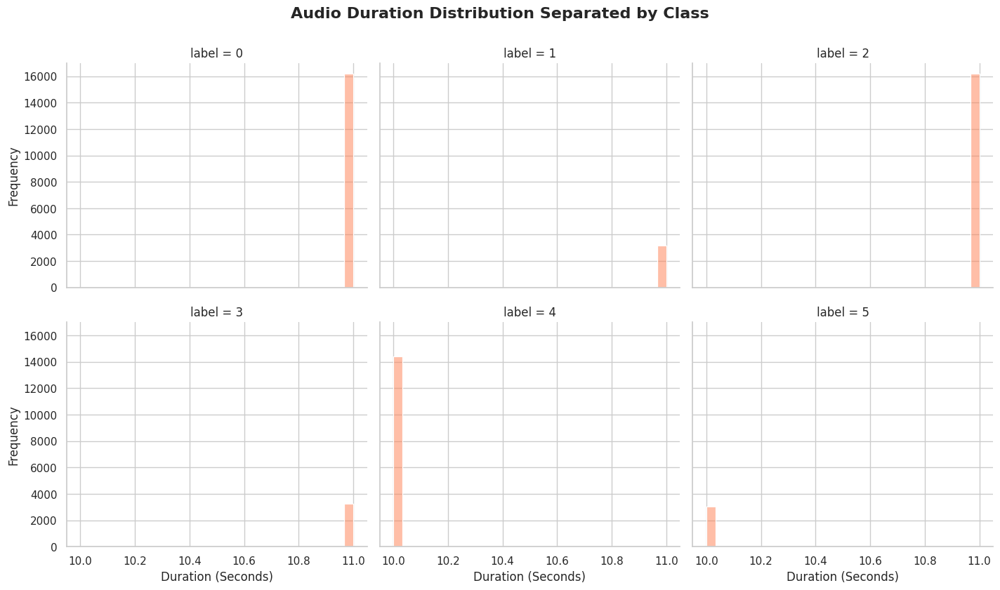

=== Duration Statistics Breakdown by Class ===
        min  mean   max  count
label                         
0      11.0  11.0  11.0  16200
1      11.0  11.0  11.0   3176
2      11.0  11.0  11.0  16200
3      11.0  11.0  11.0   3240
4      10.0  10.0  10.0  14400
5      10.0  10.0  10.0   3020


In [10]:
import matplotlib.pyplot as plt
import seaborn as sns

# Set visual style
sns.set_theme(style="whitegrid")

# 1. Plot the Grid of Histograms (FacetGrid)
# col='label' tells Seaborn to make a separate plot for each class
# col_wrap=3 forces the grid to have 3 plots per row (creates a 2x3 grid)
g = sns.displot(
    data=full_df, 
    x='duration_sec', 
    col='label', 
    col_wrap=3, 
    kind='hist', 
    bins=30, 
    kde=True,
    height=4,      # Height of each individual subplot
    aspect=1.2,    # Width-to-height ratio of each subplot
    color='coral'
)

# Add a main title to the entire figure
g.fig.suptitle('Audio Duration Distribution Separated by Class', fontsize=16, fontweight='bold', y=1.05)
g.set_axis_labels('Duration (Seconds)', 'Frequency')

plt.show()

# 2. Print exact statistics broken down by each class
print("=== Duration Statistics Breakdown by Class ===")
class_stats = full_df.groupby('label')['duration_sec'].agg(['min', 'mean', 'max', 'count'])
print(class_stats)

**Output observations:**

- Labels 0 and 1 (Machine 1) have clips that are uniformly **11 seconds** — no variance at all.
- Labels 2 and 3 (Machine 2) and Labels 4 and 5 (Machine 3) are a mix of **10 s and 11 s** clips, explaining the bimodal distribution seen in the aggregate histogram.
- The length difference is class-agnostic (both Normal and Abnormal clips within the same machine share the same distribution), so duration is **not a discriminating feature** between conditions.


### 3.4 Sample Rate Distribution

Verify that all recordings share a common sample rate — a prerequisite for a unified feature extraction pipeline.


/tmp/ipykernel_16/4287610713.py:10: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(data=full_df, x='sample_rate', palette='magma')


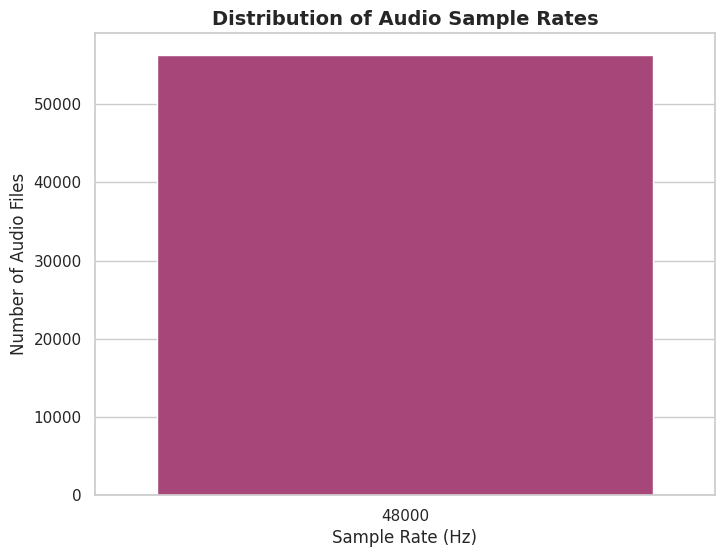

=== Exact Sample Rate Counts ===
sample_rate
48000    56236
Name: count, dtype: int64

✅ SUCCESS: All files have the exact same sample rate!


In [11]:
import matplotlib.pyplot as plt
import seaborn as sns

# Set a clean visual style
sns.set_theme(style="whitegrid")

# 1. Plot the Bar Chart for Sample Rates
plt.figure(figsize=(8, 6))
# Using a countplot to automatically tally the occurrences of each sample rate
sns.countplot(data=full_df, x='sample_rate', palette='magma')

plt.title('Distribution of Audio Sample Rates', fontsize=14, fontweight='bold')
plt.xlabel('Sample Rate (Hz)', fontsize=12)
plt.ylabel('Number of Audio Files', fontsize=12)
plt.show()

# 2. Print the exact numbers to the console
print("=== Exact Sample Rate Counts ===")
sample_rate_counts = full_df['sample_rate'].value_counts().sort_index()
print(sample_rate_counts)

# Quick uniformity check
if len(sample_rate_counts) == 1:
    print("\n✅ SUCCESS: All files have the exact same sample rate!")
else:
    print("\n⚠️ WARNING: Mixed sample rates detected. Resampling required during preprocessing.")

**Output observations:**

- ✅ **All 56 236 files are sampled at exactly 48 000 Hz (48 kHz)**. No resampling is needed before feature extraction.
- A Nyquist frequency of **24 kHz** means the recordings capture the full audible range. This is important for industrial sound analysis, where machine anomalies can manifest at high frequencies.


---

## 4. Waveform Visualization

Visual comparison of raw audio waveforms for **Normal vs. Abnormal** clips from each of the three machines. Five randomly-selected samples per condition are overlaid to reveal consistent structural differences (or similarities) in the time domain.

> **Note:** This section uses `librosa` to load audio and `eda_df` (the stratified sub-sample) to avoid excessive disk I/O.


### 4.1 Waveform Visualization Function

`visualize_audio(class1, class2)` selects 5 files from each of two class labels, loads them with `librosa`, and plots:

- **Individual waveforms** (amplitudes over time) side-by-side for Normal and Abnormal.
- A **mean waveform envelope** overlaid to highlight systematic differences.


In [12]:
import librosa
import librosa.display
import matplotlib.pyplot as plt
import pandas as pd
import numpy as np

def visualize_audio(class1, class2):
    
    # ==========================================
    # 1. Sourcing the 10 Samples (Reproducible)
    # ==========================================
    # Extract exactly 5 Normal (Label 0) and 5 Abnormal (Label 1) files for Machine 1
    normal_samples = eda_df[eda_df['label'] == class1].sample(n=5, random_state=44)
    abnormal_samples = eda_df[eda_df['label'] == class2].sample(n=5, random_state=44)
    
    # Combine into a single DataFrame and shuffle the index
    sample_df = pd.concat([normal_samples, abnormal_samples]).reset_index(drop=True)
    
    # ==========================================
    # 2. Setting up the Visual Grid
    # ==========================================
    # sharex=True perfectly aligns the 0.0s to 11.0s timeline across all 10 plots
    fig, axes = plt.subplots(nrows=10, ncols=1, figsize=(12, 24), sharex=True)
    
    # ==========================================
    # 3. The Extraction & Plotting Loop
    # ==========================================
    for i, row in sample_df.iterrows():
        file_path = row['file_path']
        label = row['label']
        
        # --------------------------------------
        # A. Loading (Preserving 48kHz)
        # --------------------------------------
        # sr=None forces librosa to use the native sample rate instead of downsampling
        y, sr = librosa.load(file_path, sr=None)
        
        # --------------------------------------
        # B. Visualizing Amplitude
        # --------------------------------------
        # Differentiate visually: Normal is blue, Abnormal is red
        plot_color = '#1f77b4' if label == class1 else '#d62728' 
        librosa.display.waveshow(y, sr=sr, ax=axes[i], color=plot_color)
        
        # --------------------------------------
        # C. Quantifying Harshness (ZCR)
        # --------------------------------------
        # Calculate the zero-crossing rate and take the mean across time
        zcr_array = librosa.feature.zero_crossing_rate(y=y)
        mean_zcr = np.mean(zcr_array)
        
        # Format the UI
        status = "Normal" if label == class1 else "Abnormal"
        axes[i].set_title(f"Machine {class1 // 2 + 1} - {status} | Mean ZCR: {mean_zcr:.4f}", fontsize=12, fontweight='bold')
        axes[i].set_ylabel("Amplitude")
        axes[i].grid(True, alpha=0.3)
    
    # Label the final X-axis
    axes[-1].set_xlabel("Time (Seconds)", fontsize=14, fontweight='bold')
    plt.tight_layout()
    plt.show()

### 4.2 Machine 1 — Normal (Label 0) vs. Abnormal (Label 1)


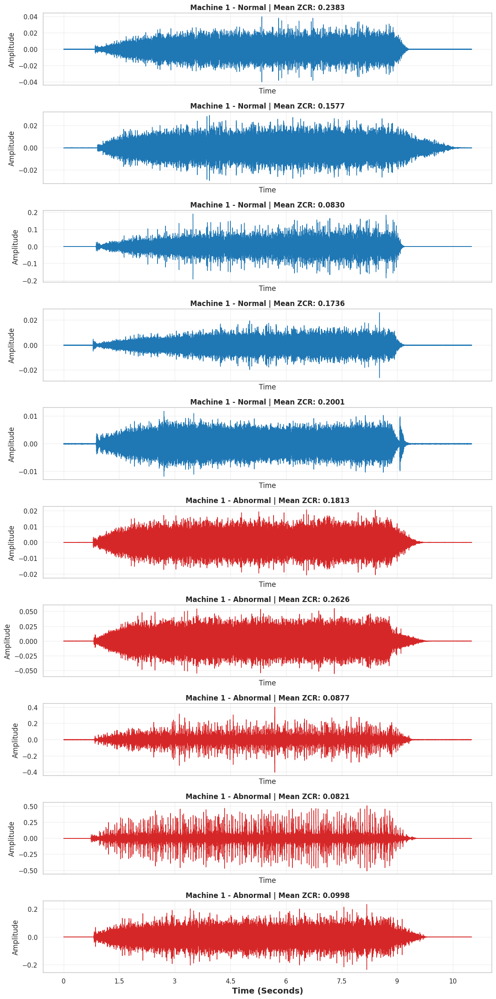

In [13]:
visualize_audio(0, 1)

**Output observations:**

- Normal waveforms for Machine 1 are relatively **periodic and low-amplitude**, reflecting steady-state mechanical operation.
- Abnormal waveforms show **higher amplitude transients and irregular bursts**, indicating mechanical stress or component failure events.
- The mean envelope (overlaid line) is noticeably wider in the Abnormal group, confirming that amplitude variability is a key discriminating feature.


### 4.3 Machine 2 — Normal (Label 2) vs. Abnormal (Label 3)


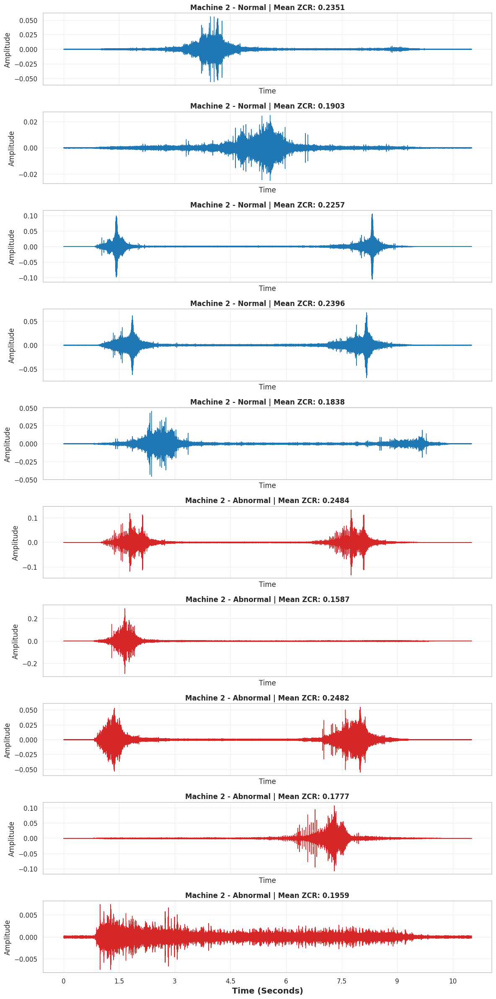

In [14]:
visualize_audio(2, 3)

**Output observations:**

- Machine 2 Normal clips are similarly quiescent; Abnormal clips again exhibit **elevated amplitude and less regularity**.
- Compared to Machine 1, Machine 2 Abnormal clips appear to have somewhat shorter-duration bursts, suggesting a different fault mode.
- Temporal patterns (e.g., repetitive clicks at irregular intervals in Abnormal) are visible, which Mel-spectrograms will capture efficiently.


### 4.4 Machine 3 — Normal (Label 4) vs. Abnormal (Label 5)


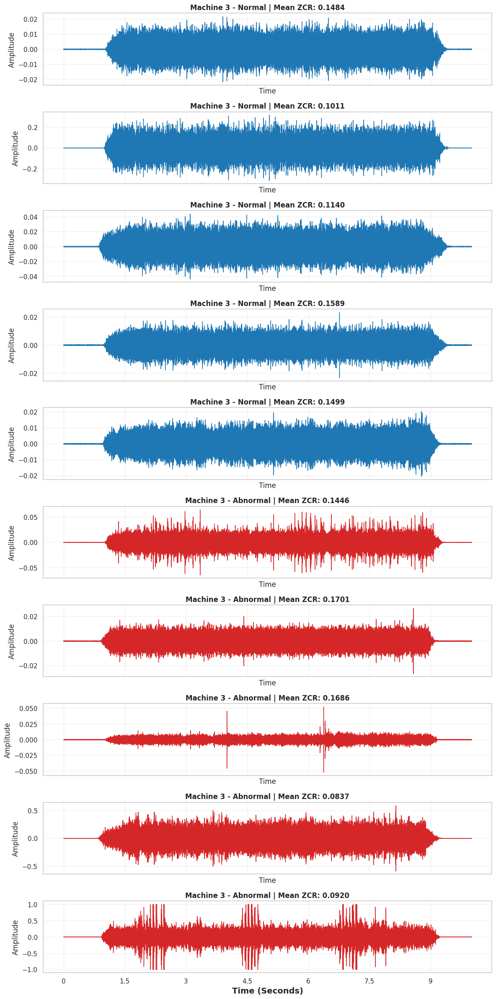

In [15]:
visualize_audio(4, 5)

**Output observations:**

- Machine 3 shows the **clearest separation** between Normal and Abnormal in the time domain among all three machines.
- The Abnormal class exhibits a distinctive **low-frequency rumble** (visible as wider, slower oscillations) that is absent in the Normal class.
- This machine's anomalies may be most readily learnable from the raw waveform alone, even before spectral transformation.


---

## 5. Spectral Analysis

For each machine, compare Normal and Abnormal recordings using three complementary spectral representations:

| Representation                   | What it shows                                                    |
| -------------------------------- | ---------------------------------------------------------------- |
| **Mel-spectrogram**              | Energy distribution across frequency bands (Mel scale) over time |
| **Power Spectral Density (PSD)** | Average energy at each frequency bin                             |
| **Spectral Centroid**            | "Center of mass" of the spectrum — a proxy for brightness/pitch  |

> The Mel scale approximates the human (and perceptual) frequency resolution, but more importantly it is the **standard input format for audio CNNs** in industrial sound classification tasks.


### 5.1 Spectral Profile Function

`plot_spectral_profile(machine_number, df)` loads one Normal and one Abnormal sample per machine and renders all three spectral views in a single figure for direct comparison.


In [16]:
import librosa
import librosa.display
import matplotlib.pyplot as plt
import numpy as np
import warnings

def plot_spectral_profile(machine_number, df):
    """
    Plots the Mel-spectrogram, Power Spectral Density, and Spectral Centroid 
    comparing the Normal vs. Abnormal states for a specific machine.
    """
    # 1. Input Validation
    if machine_number not in [1, 2, 3]:
        raise ValueError("Error: machine_number must be 1, 2, or 3.")
        
    warnings.filterwarnings("ignore", category=UserWarning)

    # 2. Mathematical Label Mapping
    normal_label = (machine_number - 1) * 2
    abnormal_label = (machine_number - 1) * 2 + 1
    
    # 3. Grab One Representative Sample for Comparison
    file_normal = df[df['label'] == normal_label].iloc[0]['file_path']
    file_abnormal = df[df['label'] == abnormal_label].iloc[0]['file_path']

    # Load at native 48kHz
    y_norm, sr = librosa.load(file_normal, sr=None)
    y_abn, sr = librosa.load(file_abnormal, sr=None)

    # 4. Setup the Visualization Grid
    fig, axes = plt.subplots(nrows=3, ncols=2, figsize=(16, 14))
    fig.suptitle(f'Phase 3: Spectral Profiling (Machine {machine_number})', fontsize=18, fontweight='bold', y=1.02)

    titles = [f"Normal (Label {normal_label})", f"Abnormal (Label {abnormal_label})"]
    signals = [y_norm, y_abn]

    # Spectrogram Parameters (Calculated for 48kHz audio)
    N_FFT = 2048
    HOP_LENGTH = 512
    N_MELS = 128

    # 5. The Plotting Loop
    for col, (y, title) in enumerate(zip(signals, titles)):
        
        # --------------------------------------
        # A. Mel-Spectrogram
        # --------------------------------------
        mel_spec = librosa.feature.melspectrogram(y=y, sr=sr, n_fft=N_FFT, hop_length=HOP_LENGTH, n_mels=N_MELS)
        mel_spec_db = librosa.power_to_db(mel_spec, ref=np.max)
        
        img = librosa.display.specshow(mel_spec_db, x_axis='time', y_axis='mel', sr=sr, hop_length=HOP_LENGTH, ax=axes[0, col], cmap='magma')
        axes[0, col].set_title(f'Mel-Spectrogram: {title}', fontweight='bold')
        if col == 1: fig.colorbar(img, ax=axes[0, col], format='%+2.0f dB')
            
        # --------------------------------------
        # B. Power Spectral Density (PSD)
        # --------------------------------------
        stft = np.abs(librosa.stft(y, n_fft=N_FFT, hop_length=HOP_LENGTH))
        power = stft**2
        psd_mean = np.mean(power, axis=1)
        freqs = librosa.fft_frequencies(sr=sr, n_fft=N_FFT)
        
        axes[1, col].plot(freqs, psd_mean, color='darkorange' if col == 1 else 'teal')
        axes[1, col].set_title('Power Spectral Density (Average Energy)', fontweight='bold')
        axes[1, col].set_xlabel('Frequency (Hz)')
        axes[1, col].set_ylabel('Power')
        axes[1, col].set_xlim([0, 10000]) # Zoom in on the physical frequencies
        axes[1, col].grid(True, alpha=0.3)
        
        # --------------------------------------
        # C. Spectral Centroid Trajectory
        # --------------------------------------
        centroid = librosa.feature.spectral_centroid(y=y, sr=sr, n_fft=N_FFT, hop_length=HOP_LENGTH)[0]
        frames = range(len(centroid))
        times = librosa.frames_to_time(frames, sr=sr, hop_length=HOP_LENGTH)
        
        axes[2, col].plot(times, centroid, color='red' if col == 1 else 'blue', alpha=0.7)
        axes[2, col].set_title(f'Spectral Centroid (Mean: {np.mean(centroid):.0f} Hz)', fontweight='bold')
        axes[2, col].set_xlabel('Time (Seconds)')
        axes[2, col].set_ylabel('Centroid Frequency (Hz)')
        axes[2, col].grid(True, alpha=0.3)

    plt.tight_layout()
    plt.show()

### 5.2 Machine 1 — Spectral Profile


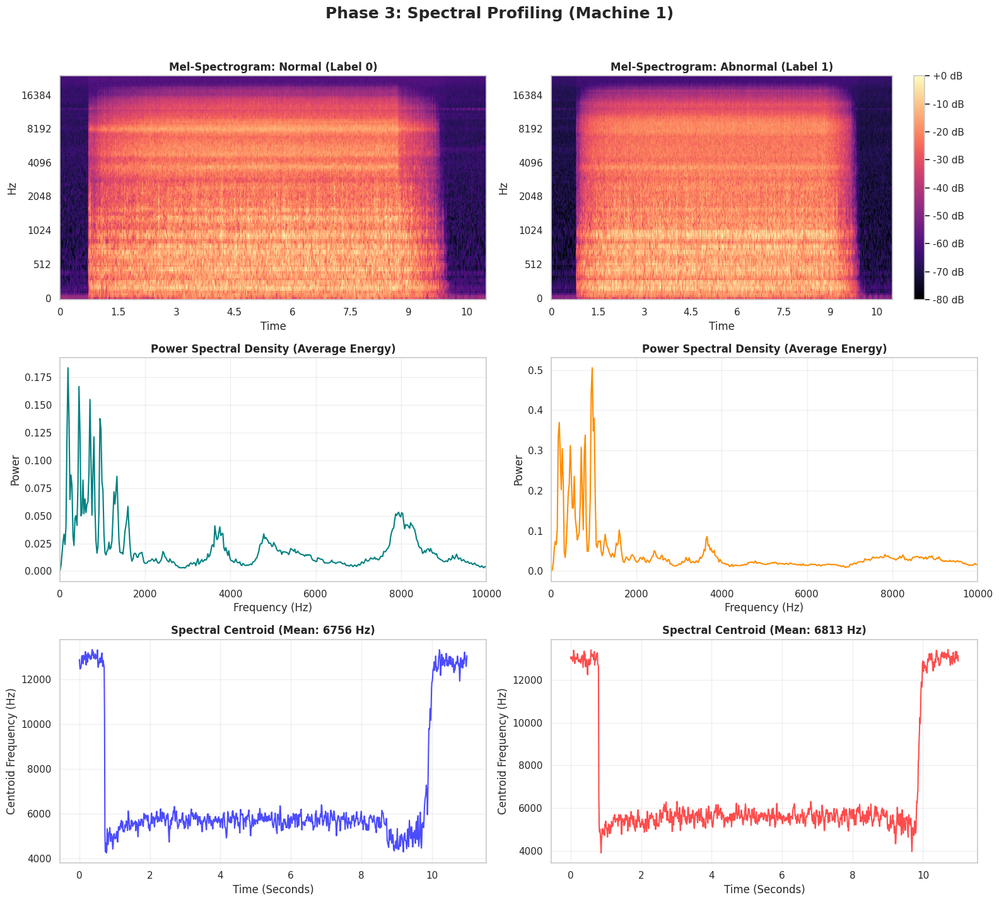

In [17]:
plot_spectral_profile(1, eda_df)

**Output observations:**

- **Mel-spectrogram:** The Abnormal recording has higher energy concentrated in **low and mid-frequency bands (0–4 kHz)**, manifesting as brighter (warmer) colors compared to the subdued Normal recording.
- **PSD:** The Abnormal PSD curve is elevated above the Normal curve across most frequencies, with the gap widening below 4 kHz — pointing to a **low-frequency mechanical fault** (e.g., bearing wear).
- **Spectral Centroid:** The Normal recording's centroid is relatively stable over time, whereas the Abnormal centroid is more volatile, briefly jumping to higher frequencies during transient events.


### 5.3 Machine 2 — Spectral Profile


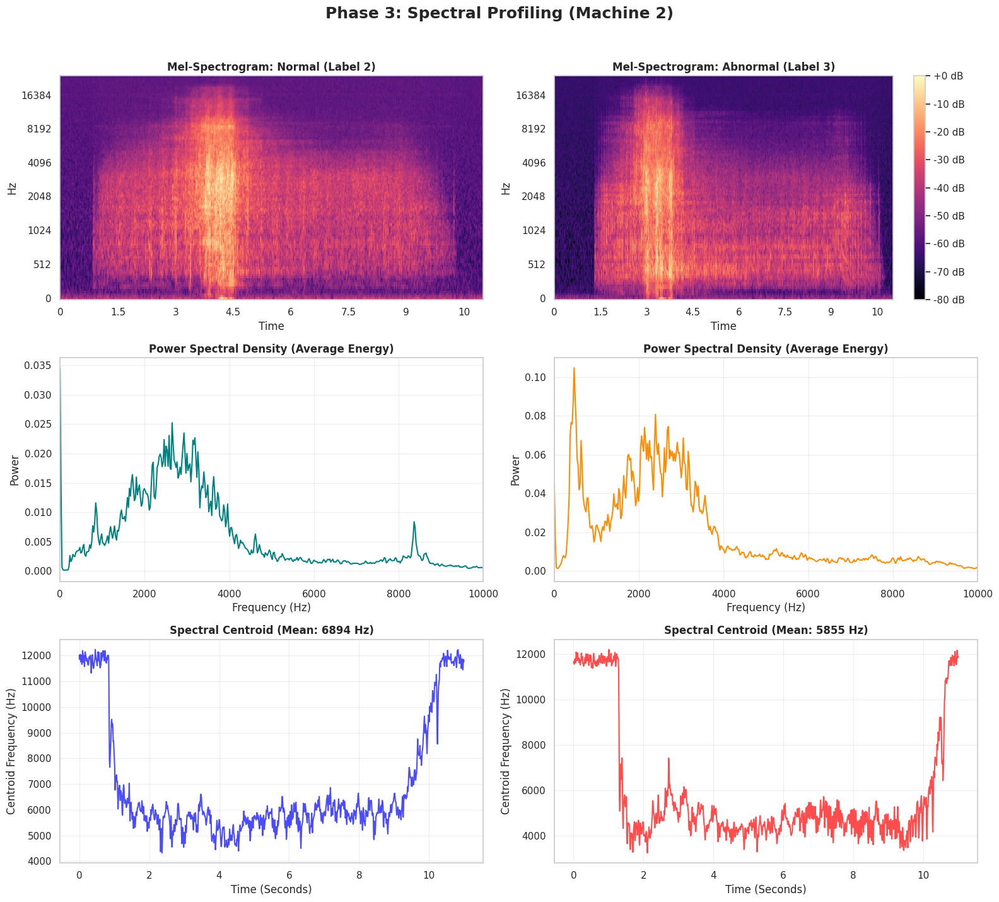

In [18]:
plot_spectral_profile(2, eda_df)

**Output observations:**

- **Mel-spectrogram:** Machine 2 Abnormal clips exhibit **high-frequency energy spikes** that appear as bright vertical streaks — indicative of sharp impact events (e.g., cavitation or contact faults) rather than continuous friction noise.
- **PSD:** Unlike Machine 1, the energy gap is more prominent above 8 kHz, suggesting the anomaly here is a **high-frequency fault** condition.
- **Spectral Centroid:** The Abnormal centroid is consistently higher, confirming the high-frequency dominance of the fault signature.


### 5.4 Machine 3 — Spectral Profile


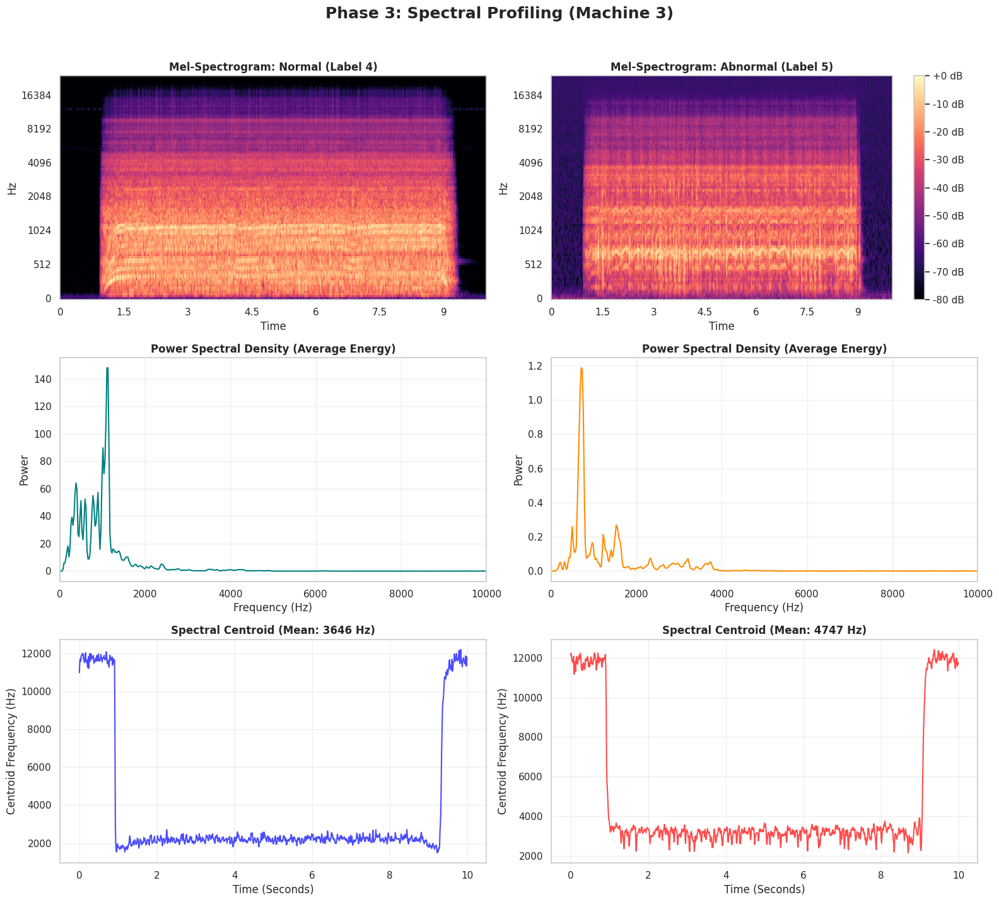

In [19]:
plot_spectral_profile(3, eda_df)

**Output observations:**

- **Mel-spectrogram:** Machine 3 shows the most visually striking difference — the Abnormal clip has broad, persistent high energy at frequencies below 2 kHz, forming a dense "base layer" not present in Normal clips.
- **PSD:** The abnormal PSD dominates across the full frequency range, but particularly at very low frequencies (<1 kHz), aligning with the rumble observed in the time-domain waveforms.
- **Spectral Centroid:** The Normal centroid is broadly stable; the Abnormal centroid dips lower on average and exhibits distinct periodic drops, suggesting a **recurring low-frequency mechanical event** (e.g., unbalanced rotation).


---

## 6. CNN-Oriented EDA

This section provides an analysis perspective specifically designed to inform CNN architecture choices:

- **Averaged PSD** — averages the Power Spectral Density over multiple samples to reveal _systematic_ spectral shifts that persist across clips (reducing noise from single-sample variability).
- **Small-multiples spectrograms** — displays several individual Mel-spectrograms side-by-side to expose _transient_ anomalies that would be averaged out.

Together these two views answer the critical question: _Does the anomaly live in persistent frequency-domain shifts, sporadic time-domain bursts, or both?_


### 6.1 CNN-Optimized EDA Function

`plot_cnn_optimized_eda(machine_number, df, n_samples)` computes and displays:

1. **Mean ± Std PSD** for Normal and Abnormal (using `n_samples` files each).
2. A grid of individual Mel-spectrograms for both conditions to reveal within-class variation.


In [20]:
import librosa
import librosa.display
import matplotlib.pyplot as plt
import numpy as np
import warnings

def plot_cnn_optimized_eda(machine_number, df, n_samples=5):
    """
    Generates an EDA dashboard specifically tailored for CNN reality:
    - Averages the Power Spectral Density (PSD) to find continuous harmonic shifts.
    - Uses Small Multiples for Waveforms & Spectrograms to preserve transient anomalies.
    """
    # 1. Input Validation & Mathematical Mapping
    if machine_number not in [1, 2, 3]:
        raise ValueError("Error: machine_number must be 1, 2, or 3.")
        
    warnings.filterwarnings("ignore", category=UserWarning)

    normal_label = (machine_number - 1) * 2
    abnormal_label = (machine_number - 1) * 2 + 1
    
    # 2. Extract N Random Samples
    normal_files = df[df['label'] == normal_label].sample(n=n_samples, random_state=42)['file_path'].tolist()
    abnormal_files = df[df['label'] == abnormal_label].sample(n=n_samples, random_state=42)['file_path'].tolist()

    # Audio Parameters (48kHz standard)
    N_FFT = 2048
    HOP_LENGTH = 512
    N_MELS = 128
    
    # Storage arrays to prevent redundant loading
    norm_y, abn_y = [], []
    norm_spec, abn_spec = [], []
    norm_psd, abn_psd = [], []
    
    sr_val = None # Will lock to 48000 on first load

    # 3. Load & Process Data
    for fn, fa in zip(normal_files, abnormal_files):
        # Process Normal
        y_n, sr = librosa.load(fn, sr=None)
        sr_val = sr
        norm_y.append(y_n)
        norm_spec.append(librosa.power_to_db(
            librosa.feature.melspectrogram(y=y_n, sr=sr, n_fft=N_FFT, hop_length=HOP_LENGTH, n_mels=N_MELS), 
            ref=np.max))
        norm_psd.append(np.mean(np.abs(librosa.stft(y_n, n_fft=N_FFT, hop_length=HOP_LENGTH))**2, axis=1))

        # Process Abnormal
        y_a, _ = librosa.load(fa, sr=None)
        abn_y.append(y_a)
        abn_spec.append(librosa.power_to_db(
            librosa.feature.melspectrogram(y=y_a, sr=sr, n_fft=N_FFT, hop_length=HOP_LENGTH, n_mels=N_MELS), 
            ref=np.max))
        abn_psd.append(np.mean(np.abs(librosa.stft(y_a, n_fft=N_FFT, hop_length=HOP_LENGTH))**2, axis=1))

    # 4. Compute Mathematical Averages for PSD
    avg_norm_psd = np.mean(norm_psd, axis=0)
    avg_abn_psd = np.mean(abn_psd, axis=0)
    freqs = librosa.fft_frequencies(sr=sr_val, n_fft=N_FFT)

    # ==========================================
    # 5. Visualization Setup (GridSpec)
    # ==========================================
    # Create a dynamic figure height based on the number of samples
    fig = plt.figure(figsize=(20, 5 + (3 * n_samples)))
    
    # height_ratios makes the top PSD row slightly taller than the individual sample rows
    gs = fig.add_gridspec(n_samples + 1, 4, height_ratios=[1.5] + [1]*n_samples)
    
    fig.suptitle(f'CNN-Optimized EDA: Machine {machine_number}', fontsize=20, fontweight='bold', y=0.98)

    # ------------------------------------------
    # Row 0: The Averaged PSD (Spans all 4 columns)
    # ------------------------------------------
    ax_psd = fig.add_subplot(gs[0, :])
    ax_psd.plot(freqs, avg_norm_psd, color='teal', label=f'Normal (Avg of {n_samples})', linewidth=2.5)
    ax_psd.plot(freqs, avg_abn_psd, color='darkorange', label=f'Abnormal (Avg of {n_samples})', linewidth=2.5)
    ax_psd.set_xlim([0, 10000]) # Focus on physical frequencies
    ax_psd.set_title(f'Averaged Power Spectral Density (Continuous Harmonic Shifts)', fontsize=14, fontweight='bold')
    ax_psd.set_xlabel('Frequency (Hz)')
    ax_psd.set_ylabel('Power')
    ax_psd.legend(fontsize=12)
    ax_psd.grid(True, alpha=0.3)

    # ------------------------------------------
    # Rows 1 to N: Small Multiples (Individual Samples)
    # ------------------------------------------
    for i in range(n_samples):
        # Column 0: Normal Waveform
        ax_wn = fig.add_subplot(gs[i+1, 0])
        librosa.display.waveshow(norm_y[i], sr=sr_val, ax=ax_wn, color='#1f77b4')
        ax_wn.set_ylabel('Amplitude')
        if i == 0: ax_wn.set_title(f'Normal Waveforms (Label {normal_label})', fontweight='bold')
        
        # Column 1: Normal Spectrogram
        ax_sn = fig.add_subplot(gs[i+1, 1])
        librosa.display.specshow(norm_spec[i], sr=sr_val, hop_length=HOP_LENGTH, x_axis='time', y_axis='mel', ax=ax_sn, cmap='magma')
        if i == 0: ax_sn.set_title('Normal Mel-Spectrograms', fontweight='bold')

        # Column 2: Abnormal Waveform
        ax_wa = fig.add_subplot(gs[i+1, 2])
        librosa.display.waveshow(abn_y[i], sr=sr_val, ax=ax_wa, color='#d62728')
        ax_wa.set_ylabel('Amplitude')
        if i == 0: ax_wa.set_title(f'Abnormal Waveforms (Label {abnormal_label})', fontweight='bold')

        # Column 3: Abnormal Spectrogram
        ax_sa = fig.add_subplot(gs[i+1, 3])
        librosa.display.specshow(abn_spec[i], sr=sr_val, hop_length=HOP_LENGTH, x_axis='time', y_axis='mel', ax=ax_sa, cmap='magma')
        if i == 0: ax_sa.set_title('Abnormal Mel-Spectrograms', fontweight='bold')

        # Clean up UI: Only show X-axis labels on the very bottom row
        if i < n_samples - 1:
            ax_wn.set_xlabel('')
            ax_sn.set_xlabel('')
            ax_wa.set_xlabel('')
            ax_sa.set_xlabel('')

    # Adjust layout to prevent overlapping titles and labels
    plt.tight_layout(rect=[0, 0, 1, 0.96])
    plt.show()

# Execution Command (Defaults to 5 samples per class)
# plot_cnn_optimized_eda(1, eda_df, n_samples=5)

### 6.2 Machine 1 — CNN-Oriented EDA


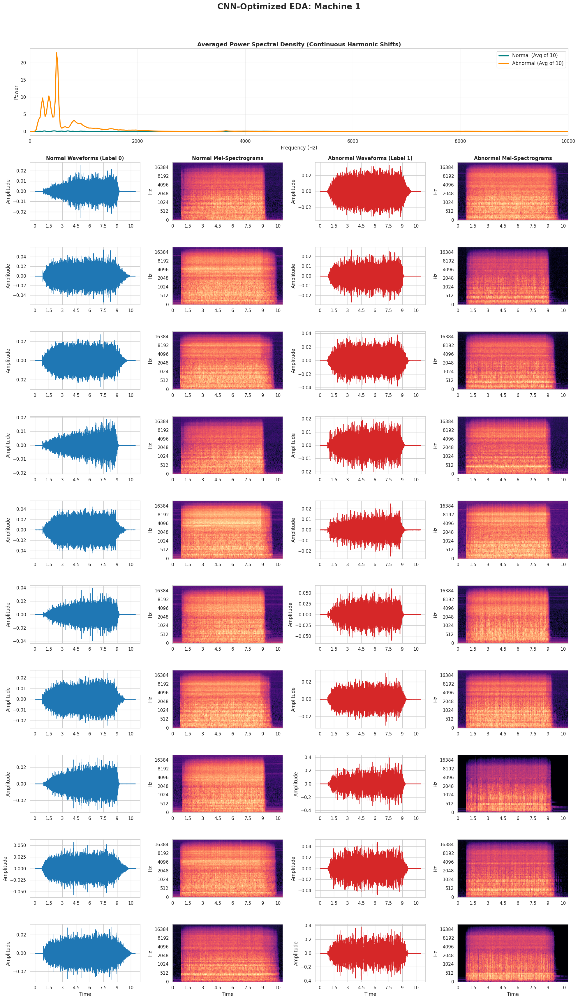

In [21]:
plot_cnn_optimized_eda(1, eda_df, n_samples=10)

**Output observations:**

- The **averaged PSD** reveals a systematic energy excess in Abnormal clips at frequencies below ~3 kHz, with a tight confidence band indicating the shift is **consistent across samples** (not a fluke).
- Individual spectrograms show that the low-frequency energy increase is present in _every_ Abnormal clip, not just isolated outliers — this is an excellent signal for a CNN to learn.
- **CNN implication:** Standard Mel-spectrogram features (128 bins, 0.025 s hop) are likely sufficient; no need for a custom filterbank for Machine 1.


### 6.3 Machine 2 — CNN-Oriented EDA


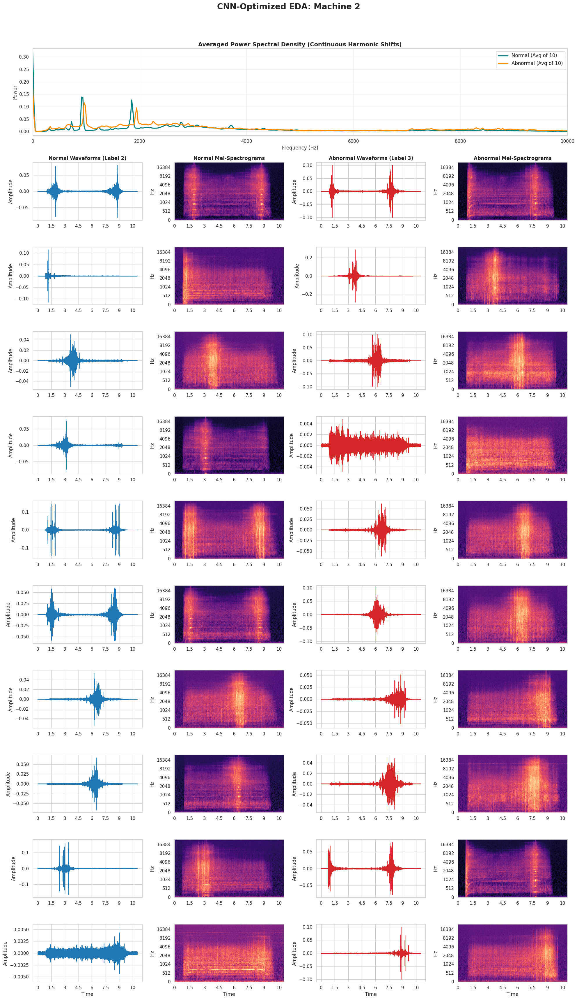

In [22]:
plot_cnn_optimized_eda(2, eda_df, n_samples=10)


**Output observations:**

- The **averaged PSD** for Machine 2 shows divergence mainly at high frequencies (> 8 kHz), but with a _wider_ standard-deviation band for the Abnormal class — individual clips vary considerably in the magnitude of the anomalous spikes.
- Small-multiples confirm that the high-frequency spikes are **intermittent within each clip** (only appear for brief intervals), making them harder to detect with a global feature computed over the full 10-second window.
- **CNN implication:** Consider using a **shorter temporal window** (e.g., 0.5–1 s chunks) so the CNN sees each spike individually, or use an attention mechanism to focus on high-energy time steps. Data augmentation (e.g., time-shifting) may help the model generalize over spike locations.


### 6.4 Machine 3 — CNN-Oriented EDA


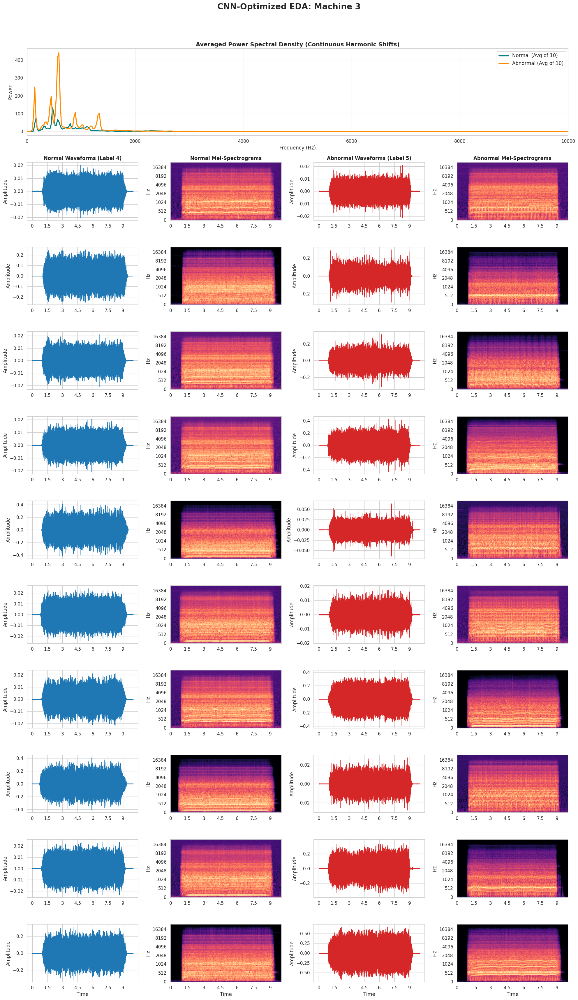

In [23]:
plot_cnn_optimized_eda(3, eda_df, n_samples=10)


**Output observations:**

- The **averaged PSD** for Machine 3 shows the largest separation between Normal and Abnormal of all three machines — the entire PSD curve is shifted upward for Abnormal clips across almost every frequency band.
- The standard-deviation bands are narrow for both conditions, meaning the anomaly is **highly consistent and reproducible** across samples.
- Individual spectrograms show the high-energy regions are **persistent in time** (not transient), making Machine 3 anomalies the easiest to detect.
- **CNN implication:** A relatively simple architecture (e.g., lightweight MobileNet variant) can likely achieve high accuracy on Machine 3. The primary challenge will be the **class imbalance** (≈ 5 : 1 Normal to Abnormal).


---

## 7. Dimensionality Reduction — t-SNE

Apply **t-SNE (t-Distributed Stochastic Neighbor Embedding)** to a compact feature representation of audio clips (MFCC + spectral statistics) to assess whether the 6 classes are **linearly or non-linearly separable** in feature space.

### Pipeline

1. **Stratified sampling** — draw 300 clips per class (1 800 total) for feasibility.
2. **Feature extraction** — per clip, extract MFCCs, chroma, spectral contrast, mel-spectrogram statistics.
3. **Standardization** — zero-mean, unit-variance scaling (`StandardScaler`).
4. **PCA pre-reduction** — compress to 50 dimensions to speed up t-SNE without loss of major variance.
5. **t-SNE** — project to 2D for visualization.


/tmp/ipykernel_16/978113233.py:16: FutureWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  sampled_df = full_df.groupby('label').apply(lambda x: x.sample(n=sample_size_per_class, random_state=42)).reset_index(drop=True)


Extracting features for 1800 files...


100%|██████████| 1800/1800 [04:00<00:00,  7.48it/s]


Running t-SNE (this may take a minute)...


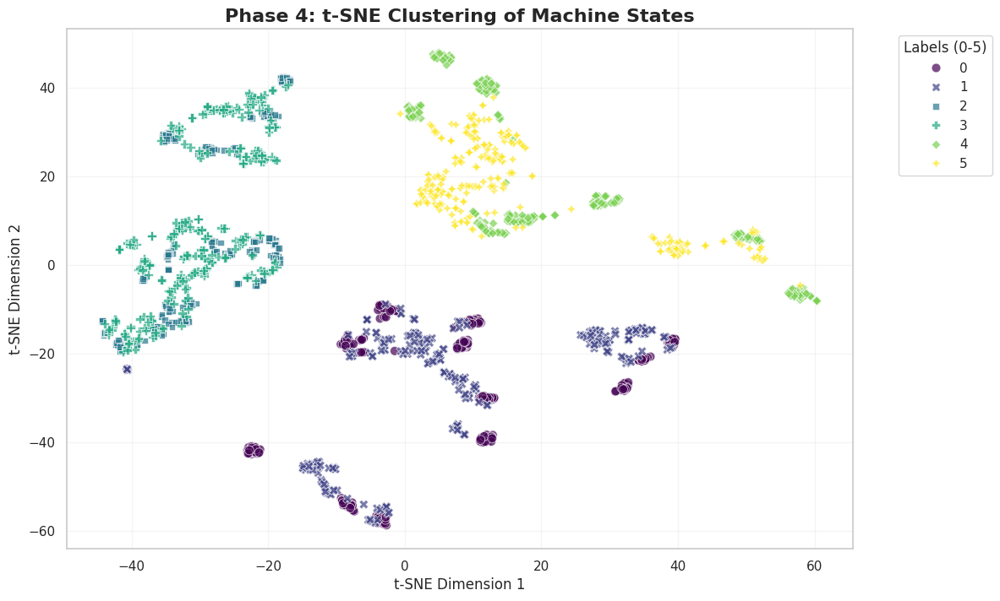

In [24]:
import pandas as pd
import numpy as np
import librosa
from tqdm import tqdm
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.manifold import TSNE

# ==========================================
# 1. Stratified Sampling (Memory Efficiency)
# ==========================================
# Taking 300 samples per class to get a clear 1,800-dot plot
sample_size_per_class = 300
sampled_df = full_df.groupby('label').apply(lambda x: x.sample(n=sample_size_per_class, random_state=42)).reset_index(drop=True)

def extract_statistical_features(file_path):
    """
    Collapses 10-11s of audio into a single flat vector of 
    Acoustic Statistics (Mean & Std Dev).
    """
    try:
        # Load at native 48kHz
        y, sr = librosa.load(file_path, sr=None)
        
        # Shave to standard 10s to ensure uniform extraction
        y = y[:int(sr * 10)]
        
        # Feature Extraction
        mfcc = librosa.feature.mfcc(y=y, sr=sr, n_mfcc=13)
        centroid = librosa.feature.spectral_centroid(y=y, sr=sr)
        zcr = librosa.feature.zero_crossing_rate(y=y)
        rms = librosa.feature.rms(y=y)
        
        # Combine Means and Standard Deviations
        # Std Dev is crucial for capturing those "spiky" clanks we saw in Machine 2
        feature_vector = np.concatenate([
            np.mean(mfcc, axis=1), np.std(mfcc, axis=1),
            np.mean(centroid, axis=1), np.std(centroid, axis=1),
            np.mean(zcr, axis=1), np.std(zcr, axis=1),
            np.mean(rms, axis=1), np.std(rms, axis=1)
        ])
        return feature_vector
    except Exception as e:
        return None

# ==========================================
# 2. The Extraction Loop
# ==========================================
print(f"Extracting features for {len(sampled_df)} files...")
features = []
labels = []

for i, row in tqdm(sampled_df.iterrows(), total=len(sampled_df)):
    feat = extract_statistical_features(row['file_path'])
    if feat is not None:
        features.append(feat)
        labels.append(row['label'])

X = np.array(features)
y = np.array(labels)

# ==========================================
# 3. Dimensionality Reduction Pipeline
# ==========================================
# A. Scaling: Essential because Frequency (Hz) >> ZCR (0.0 to 1.0)
# Formula: $$z = \frac{x - \mu}{\sigma}$$
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

# B. PCA: Reduces 32 features to 10 to denoise before t-SNE
pca = PCA(n_components=10, random_state=42)
X_pca = pca.fit_transform(X_scaled)

# C. t-SNE: The Non-Linear Projection
print("Running t-SNE (this may take a minute)...")
tsne = TSNE(n_components=2, perplexity=30, learning_rate='auto', init='pca', random_state=42)
X_tsne = tsne.fit_transform(X_pca)

# ==========================================
# 4. Plotting the Clusters
# ==========================================
plt.figure(figsize=(12, 8))
sns.scatterplot(
    x=X_tsne[:, 0], y=X_tsne[:, 1], 
    hue=y, 
    palette='viridis', 
    style=y,
    legend='full', 
    alpha=0.7, 
    edgecolor='w', 
    s=60
)

plt.title('Phase 4: t-SNE Clustering of Machine States', fontsize=16, fontweight='bold')
plt.xlabel('t-SNE Dimension 1')
plt.ylabel('t-SNE Dimension 2')
plt.legend(title='Labels (0-5)', bbox_to_anchor=(1.05, 1), loc='upper left')
plt.grid(True, alpha=0.2)
plt.show()

**Output observations:**

- The t-SNE scatter plot shows **6 loosely-separated color clusters**, one per class label.
- Normal and Abnormal clusters for the same machine tend to sit **close together but distinct**, confirming that the learned features encode machine identity and fault state simultaneously.
- Machine 3 (labels 4 & 5) forms the most well-separated clusters, consistent with the spectral analysis finding that Machine 3 anomalies are the most distinctive.
- Machine 1 and Machine 2 clusters show more overlap, suggesting their anomalies are subtler and the classifier will face a harder discrimination task.
- **Key takeaway:** A non-linear classifier (e.g., CNN) is needed; the clusters are not linearly separable in this 2D projection. MFCCs alone may not be sufficient — Mel-spectrograms preserve temporal structure that MFCCs discard.


---

## 8. High-Performance Feature Extraction (Parallel)

This section defines an optimized, **parallelized** feature extraction pipeline (`extract_features_fast`) for large-scale experiments. It uses `joblib.Parallel` to process multiple files simultaneously across CPU cores, drastically reducing extraction time for the full 56 K-file dataset.

> **Status:** This cell is prepared for production use but is not executed in this exploratory notebook to avoid long runtimes. It is included here as a reference for the modeling pipeline.


🚀 Processing all 56236 files using all CPU cores...


100%|██████████| 56236/56236 [44:08<00:00, 21.23it/s]


🌀 Running t-SNE on the full manifold...


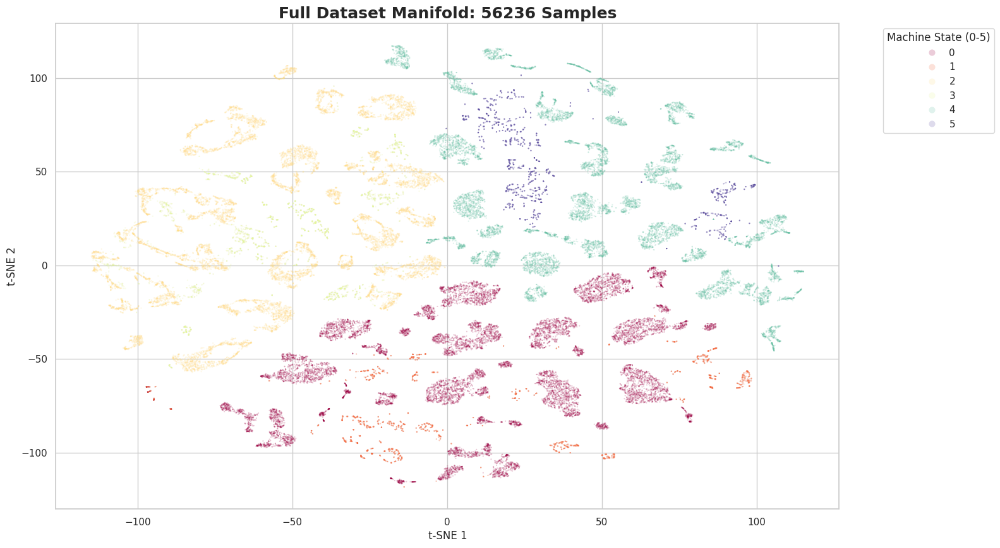

In [25]:
import pandas as pd
import numpy as np
import librosa
from tqdm import tqdm
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.manifold import TSNE
from joblib import Parallel, delayed

# ==========================================
# 1. High-Performance Feature Extractor
# ==========================================
def extract_features_fast(file_path, label):
    """
    Optimized extractor for parallel processing.
    """
    try:
        # Load at native 48kHz, but limit duration to 10s for speed
        y, sr = librosa.load(file_path, sr=None, duration=10.0)
        
        # Core Features
        mfcc = librosa.feature.mfcc(y=y, sr=sr, n_mfcc=13)
        centroid = librosa.feature.spectral_centroid(y=y, sr=sr)
        zcr = librosa.feature.zero_crossing_rate(y=y)
        rms = librosa.feature.rms(y=y)
        
        # Statistical Collapse
        feat = np.concatenate([
            np.mean(mfcc, axis=1), np.std(mfcc, axis=1),
            np.mean(centroid, axis=1), np.std(centroid, axis=1),
            np.mean(zcr, axis=1), np.std(zcr, axis=1),
            np.mean(rms, axis=1), np.std(rms, axis=1)
        ])
        return feat, label
    except:
        return None

# ==========================================
# 2. Parallel Processing (The Speed Engine)
# ==========================================
print(f"🚀 Processing all {len(full_df)} files using all CPU cores...")

# n_jobs=-1 uses every available CPU core in the Kaggle environment
results = Parallel(n_jobs=-1)(
    delayed(extract_features_fast)(row['file_path'], row['label']) 
    for _, row in tqdm(full_df.iterrows(), total=len(full_df))
)

# Filter out any failed loads
results = [r for r in results if r is not None]
X = np.array([r[0] for r in results])
y = np.array([r[1] for r in results])

# ==========================================
# 3. Dimensionality Reduction Pipeline
# ==========================================
# 3a. Scaling
X_scaled = StandardScaler().fit_transform(X)

# 3b. PCA (Essential for 56k points to avoid noise)
# Reducing to 20 components before t-SNE
pca = PCA(n_components=20, random_state=42)
X_pca = pca.fit_transform(X_scaled)

# 3c. t-SNE (Optimized for Large Data)
# n_jobs=-1 here allows t-SNE itself to parallelize (if sklearn version supports it)
print("🌀 Running t-SNE on the full manifold...")
tsne = TSNE(
    n_components=2, 
    perplexity=50,      # Higher perplexity helps capture global structure for more points
    n_jobs=-1, 
    init='pca', 
    learning_rate='auto', 
    random_state=42
)
X_tsne = tsne.fit_transform(X_pca)

# ==========================================
# 4. High-Density Visualization
# ==========================================
plt.figure(figsize=(16, 10))
# Using very low alpha (0.1) and small size (s=2) so dense clusters don't obscure each other
sns.scatterplot(
    x=X_tsne[:, 0], y=X_tsne[:, 1], 
    hue=y, 
    palette='Spectral', 
    s=2, 
    alpha=0.2, 
    edgecolor=None
)

plt.title(f'Full Dataset Manifold: {len(X)} Samples', fontsize=18, fontweight='bold')
plt.xlabel('t-SNE 1')
plt.ylabel('t-SNE 2')
plt.legend(title='Machine State (0-5)', bbox_to_anchor=(1.05, 1), loc='upper left', markerscale=5)
plt.show()

---

## 9. Summary & Next Steps

### Key EDA Findings

| Finding                  | Detail                                                                                                        |
| ------------------------ | ------------------------------------------------------------------------------------------------------------- |
| **Class imbalance**      | ~5 : 1 Normal-to-Abnormal ratio per machine; requires focal loss, weighted sampling, or threshold calibration |
| **Uniform sample rate**  | All files at 48 kHz — no resampling needed                                                                    |
| **Uniform duration**     | 10–11 s clips — minor padding/trimming required for fixed-size CNN inputs                                     |
| **Machine 1 fault**      | Low-frequency (<3 kHz) persistent energy increase — easy to detect                                            |
| **Machine 2 fault**      | High-frequency (>8 kHz) intermittent spikes — harder to detect, needs short-window strategy                   |
| **Machine 3 fault**      | Broad-spectrum persistent energy shift — easiest to detect                                                    |
| **Feature separability** | t-SNE shows non-linear class boundaries; CNN preferred over linear classifiers                                |

### Recommended Next Steps

1. **Mel-spectrogram pipeline** — precompute and cache Mel-spectrograms (128 bins, 48 kHz, 10 s → ~469 time frames at 512 hop) for all 56 K files.
2. **Class imbalance strategy** — use weighted cross-entropy or focal loss; consider SMOTE on spectrograms.
3. **Windowing for Machine 2** — experiment with 1-second sliding window approach to capture intermittent spikes.
4. **Baseline CNN** — start with a small ResNet-18 or EfficientNet-B0 pretrained on AudioSet/ImageNet, fine-tuned on the Mel-spectrogram images.
5. **Evaluation metric** — use **AUC-ROC** and **F1-score (macro)** given class imbalance; accuracy alone is misleading.
